# El protocolo del propio artículo: el ajuste de la Tabla 5 juzgado dentro de la muestra, frente a los mismos diez muestreos retenidos

**Pregunta:** ¿Qué dice sobre el modelo del HP500 el protocolo dentro de la muestra del estado del arte, un ajuste juzgado con los mismos diez muestreos a los que se ajustó, y qué cambia cuando en cambio se retiene cada muestreo?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los notebooks 01 y 02 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir cuál es el estado del arte sobre este chancador, y qué protocolo usa para juzgar su propio modelo;
- ejecutar ese protocolo con los diez muestreos, ajustando la física, el residuo acotado y una regresión sin restricciones con las diez filas mediante las funciones públicas de CrusherCal;
- leer cada coeficiente ajustado por su sentido físico, y decir por qué un buen número dentro de la muestra no puede decidir entre los modelos;
- poner los errores dentro de la muestra junto a los errores con retención de los mismos modelos en ambos objetivos, y leer el optimismo.

## Preparación

Numpy y matplotlib. Las funciones de CrusherCal vienen de la carpeta `hp500` del pipeline, que solo necesita numpy.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

La celda importa el lector de muestreos, el motor, el constructor del modelo base y el módulo CrusherCal, cuyas funciones públicas ajustan los modelos. Cada importación del pipeline lleva su comentario.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
# el lector que valida la tabla de muestreos
from pipeline.hp500.surveys import read_surveys
# el motor y el punto de operación de la vía calibrada
from pipeline.model.crusher import evaluate, operating_from_survey
# la base de capacidad, las dos potencias del motor y el índice de trabajo de la mezcla
from pipeline.model.crusher.capacity import HP500_QREF, bond_power, calibrated_power
from pipeline.model.crusher.hp500 import HP500_BLEND_WI_KWH_T
# el documento del modelo base y CrusherCal
from pipeline.hp500 import backbone, loo
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, y `VERSION`, la etiqueta de versión que lleva el documento del modelo base. Los dos objetivos medidos son el tonelaje en t/h y la potencia en kW.

La celda lee la tabla y la etiqueta de versión y deja los dos objetivos medidos y los dos regresores del modelo libre.

In [2]:
# Lea la tabla de muestreos y la etiqueta de versión; deje los dos objetivos medidos y los regresores
surveys = read_surveys().accepted
version = (ROOT / "VERSION").read_text(encoding="utf-8").strip()
measured_q = np.array([s.feed_tph for s in surveys])
measured_kw = np.array([s.power_kw for s in surveys])
features = np.column_stack([[s.css_mm for s in surveys], [s.f80_mm for s in surveys]])
targets = {"tph": measured_q, "kW": measured_kw}
print("muestreos:", len(surveys), "| etiqueta de versión:", version)

muestreos: 10 | etiqueta de versión: 0.09.003


## Método

**El lado del producto: el modelo base calibrado.** El modelo base es la vía calibrada del motor con sus constantes publicadas: la base de capacidad $Q_T \approx 647$ t/h y la forma de potencia $P_c = 1{,}30\,P_d + 110$ kW (Rocha et al., 2024; https://doi.org/10.3390/min14090919), donde $P_d$ es la potencia de Bond del motor. CrusherCal convierte cada una de estas constantes en un escalar que puede reajustarse a las filas que se le den. La celda ejecuta el motor en los diez muestreos e imprime las dos entradas, el factor de capacidad y la potencia de Bond, como en el notebook 02.

In [3]:
# Las entradas de los dos modelos base, a 0,01 como las llevan los documentos versionados: capacidad y potencia de Bond
runs = [evaluate(operating_from_survey(s.css_mm, s.f80_mm)) for s in surveys]
shape = np.array([r.throughput_tph for r in runs]).round(2) / HP500_QREF
bond_kw = np.array([bond_power(r.throughput_tph, r.f80, r.p80, HP500_BLEND_WI_KWH_T) for r in runs]).round(2)
print("factor de capacidad por muestreo:", shape.round(3))
print("potencia de Bond por muestreo [kW]:", bond_kw.round(1))

factor de capacidad por muestreo: [1.868 1.868 1.711 1.711 1.711 1.5   1.447 1.605 1.5   1.895]
potencia de Bond por muestreo [kW]: [229.5 233.7 224.9 225.7 234.8 222.5 196.1 212.7 221.6 237.5]


**El protocolo, paso 1: ajustar la física con las diez filas.** El protocolo dentro de la muestra usa todos los muestreos para ajustar y luego juzga con los mismos muestreos. En CrusherCal esto es la variante con fuga del pliegue, `fold_indices(10, i, leaky=True)`, cuyas filas de entrenamiento son las diez. La celda ajusta la base de capacidad con `fit_capacity_base` (un escalar de mínimos cuadrados, $Q_T = \sum s\,m / \sum s^2$) y la forma de potencia con `fit_power_form` (el par $\zeta$, $P_n$ por mínimos cuadrados ordinarios), y los imprime junto a las constantes publicadas.

In [4]:
# Ajuste la física con los diez muestreos, como el estado del arte: una base de capacidad y una forma de potencia
everyone = loo.fold_indices(10, 0, leaky=True)
qt = loo.fit_capacity_base(shape, measured_q, everyone)
zeta, pn = loo.fit_power_form(bond_kw, measured_kw, everyone)
print("filas ajustadas:", everyone.tolist())
print(f"base de capacidad: reajustada {qt:.1f} t/h | la del artículo {HP500_QREF} t/h")
print(f"forma de potencia Pc = zeta Pd + Pn: zeta = {zeta:.4f}, Pn = {pn:.1f} kW | las del artículo 1,30 y 110 kW")

filas ajustadas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
base de capacidad: reajustada 686.0 t/h | la del artículo 647 t/h
forma de potencia Pc = zeta Pd + Pn: zeta = -2.4146, Pn = 828.6 kW | las del artículo 1,30 y 110 kW


La base de capacidad reajustada es 686,0 t/h, 6 por ciento sobre los 647 t/h del artículo, un movimiento pequeño y físico de un solo número. La forma de potencia es otra cosa: el óptimo dentro de la muestra es $\zeta = -2{,}4146$ con $P_n = 828{,}6$ kW, una recta de pendiente negativa en la que más potencia de Bond predice menos potencia medida, y una eficiencia negativa no tiene sentido físico. Aparece porque la potencia de Bond varía poco (196 a 238 kW, notebook 02) frente a una potencia medida que abarca de 187 a 355 kW y que está correlacionada negativamente con ella, de modo que la regresión inclina su recta hacia abajo para seguir la variación entre muestreos: ajusta la dispersión, no la física. La segunda figura de este notebook dibuja esa recta.

**El protocolo, paso 2: la regresión libre y el modelo de residuo.** Los otros dos modelos de CrusherCal se ajustan con las mismas diez filas. M2 es un plano de mínimos cuadrados ordinarios en la abertura y el f80 (`fit_freeform`), tres coeficientes por objetivo y ninguna física. M1 suma al modelo base un residuo ridge (`fit_residual`, penalización 1, recortado a 20 por ciento del modelo base), cuyos coeficientes están en variables estandarizadas. La celda imprime los coeficientes de ambos y guarda las predicciones dentro de la muestra de los cuatro modelos: el modelo base M0, M1, M2 y la media constante.

In [5]:
# Los cuatro modelos ajustados con las diez filas, y sus predicciones dentro de la muestra para ambos objetivos
fitted = {("tph", "M0"): qt * shape, ("kW", "M0"): zeta * bond_kw + pn}
for key, y in targets.items():
    plane = loo.fit_freeform(features, y, everyone)
    fitted[key, "M2"] = np.array([loo.predict_freeform(plane, x) for x in features])
    fitted[key, "mean"] = np.full(10, y.mean())
    fits = [loo.fit_residual(features, fitted[key, "M0"], y, everyone, i) for i in range(10)]
    fitted[key, "M1"] = fitted[key, "M0"] + np.array([f.clipped for f in fits])
    print(key, "coeficientes de M2 (intercepto, abertura, f80):", np.round(plane, 2))
    print(key, "coeficientes ridge de M1 (intercepto, abertura, f80):", np.round(fits[0].coef, 1))

tph coeficientes de M2 (intercepto, abertura, f80): [-802.3    36.56    2.68]
tph coeficientes ridge de M1 (intercepto, abertura, f80): [-7.7 95.7 56.7]
kW coeficientes de M2 (intercepto, abertura, f80): [ 7.7653e+02 -9.4200e+00 -5.3000e-01]
kW coeficientes ridge de M1 (intercepto, abertura, f80): [  0.  -34.8 -24.1]


La regresión libre tiene tres coeficientes por objetivo, frente al único escalar del modelo base de tonelaje, y el coeficiente de la abertura de su plano de tonelaje, +36,6 t/h por milímetro de abertura, es el único de ellos que se lee como física. El plano de potencia tiene un coeficiente de abertura negativo, -9,42 kW por milímetro, que es lo que hace la potencia medida al abrir la abertura. Estos coeficientes son lo que el protocolo dentro de la muestra puede doblar libremente hacia los diez puntos, y la celda siguiente cuenta lo que eso compra.

**El protocolo, paso 3: juzgar dentro de la muestra.** El error de cada modelo en los muestreos a los que se ajustó, como lo informa el estado del arte, con `loo.mape`. Vienen dos filas de referencia: el modelo base tal como se entrega, cuyas constantes son los 647 t/h y los 1,30 y 110 kW del artículo y que este notebook no reajustó, y la potencia de Bond pura para el objetivo de potencia.

In [6]:
# MAPE dentro de la muestra de los cuatro modelos, y del modelo base con las constantes del artículo
shipped = {"tph": np.array([r.throughput_tph for r in runs]),
           "kW": np.array([calibrated_power(v) for v in bond_kw])}
models = ("M0", "M1", "M2", "mean")
in_sample = {(key, m): loo.mape(y, fitted[key, m]) for key, y in targets.items() for m in models}
labels = {"M0": "M0", "M1": "M1", "M2": "M2", "mean": "media"}
for key, y in targets.items():
    print(key, {labels[m]: round(in_sample[key, m], 2) for m in models})
    print(f"     constantes del artículo {loo.mape(y, shipped[key]):6.2f} %")
print("     potencia de Bond pura en el objetivo de potencia:", round(loo.mape(measured_kw, bond_kw), 2), "%")

tph {'M0': 10.95, 'M1': 8.51, 'M2': 8.24, 'media': 16.46}
     constantes del artículo  11.55 %
kW {'M0': 19.28, 'M1': 12.0, 'M2': 9.46, 'media': 22.03}
     constantes del artículo  47.58 %
     potencia de Bond pura en el objetivo de potencia: 26.88 %


## Estado del arte

**La fuente.** El estado del arte sobre esta máquina es Rocha, Campos, Silva y Tavares (2024; https://doi.org/10.3390/min14090919): un modelo fit-for-purpose del HP500, con los parámetros de clasificación y de quiebre de Andersen-Whiten, la capacidad y la potencia, ajustado a los diez muestreos y juzgado con ellos. Su protocolo es el habitual para esos modelos, un ajuste dentro de la muestra: las constantes salen de los diez muestreos, y la concordancia del modelo con los mismos diez muestreos es la evidencia. La literatura vecina sobre sustitutos aprendidos de modelos de conminución tiene la misma forma: Koh et al. (2021; https://doi.org/10.1016/j.mineng.2021.107026) juzgan una red frente al modelo que emula, no frente a una planta retenida.

Un ajuste dentro de la muestra no es erróneo; responde una pregunta distinta de "cómo le irá en el próximo muestreo". Las celdas anteriores ejecutaron ese protocolo con las funciones públicas del pipeline, y la fila dentro de la muestra de cada modelo es la evidencia que informaría el estado del arte. La celda siguiente ejecuta el protocolo del producto con las mismas filas, `loo.build` de CrusherCal, que reajusta cada escalar sin el muestreo retenido en cada uno de los diez pliegues, y pone los dos tipos de error lado a lado. Este es el único lugar del tema donde se tabulan juntos los errores dentro de la muestra y con retención; los notebooks 01, 02 y 04 calculan lo que cada uno agrega.

In [7]:
# El protocolo del producto con las mismas filas: CrusherCal con retención, y la tabla de los dos errores
names = {"M0": "M0_backbone", "M1": "M1_residual", "M2": "M2_freeform", "mean": "constant_mean"}
doc = loo.build(backbone.build(surveys, version), version)
held_out = {(key, m): doc["loo"][key]["strict"][names[m]]["mape_pct"] for key in targets for m in models}
print("objetivo modelo  dentro de la muestra  con retención  optimismo")
for key in targets:
    for m in models:
        a, b = in_sample[key, m], held_out[key, m]
        print(f"{key:8s} {labels[m]:6s} {a:12.2f} % {b:12.2f} % {b - a:+9.2f}")

objetivo modelo  dentro de la muestra  con retención  optimismo
tph      M0            10.95 %        12.09 %     +1.14
tph      M1             8.51 %        13.45 %     +4.94
tph      M2             8.24 %        12.18 %     +3.94
tph      media         16.46 %        18.29 %     +1.83
kW       M0            19.28 %        25.94 %     +6.66
kW       M1            12.00 %        25.37 %    +13.37
kW       M2             9.46 %        14.03 %     +4.57
kW       media         22.03 %        24.48 %     +2.45


La figura dibuja la tabla: para cada objetivo, el error dentro de la muestra y el error con retención de los cuatro modelos, lado a lado.

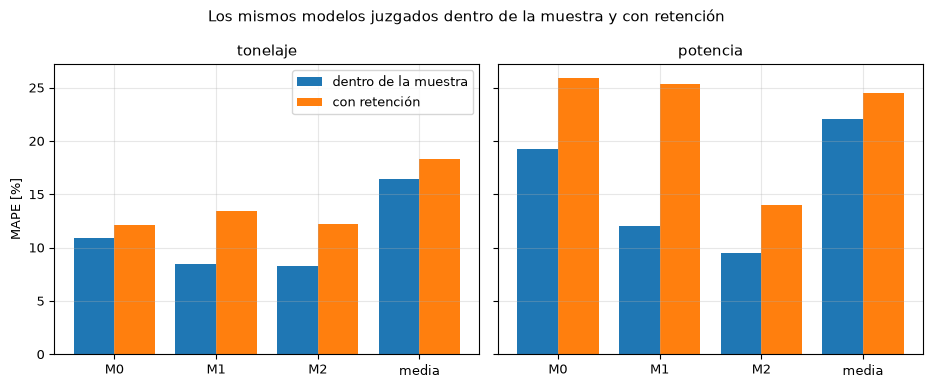

In [8]:
# Barras del error dentro de la muestra y con retención de los cuatro modelos, un panel por objetivo
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
x = np.arange(len(models))
for ax, key, label in zip(axes, targets, ("tonelaje", "potencia")):
    ax.bar(x - 0.2, [in_sample[key, m] for m in models], 0.4, label="dentro de la muestra")
    ax.bar(x + 0.2, [held_out[key, m] for m in models], 0.4, label="con retención")
    ax.set_xticks(x, ["M0", "M1", "M2", "media"])
    ax.set_title(label)
axes[0].set_ylabel("MAPE [%]")
axes[0].legend()
fig.suptitle("Los mismos modelos juzgados dentro de la muestra y con retención")
fig.tight_layout()
plt.show()

Leída como la lee el estado del arte, la mitad dentro de la muestra de la historia es favorable: en tonelaje el modelo base tal como se entrega, con 11,55 por ciento, y el M0 reajustado, con 10,95, superan a la media constante con 16,46, y en potencia la forma reajustada, con 19,28 por ciento, supera a la media con 22,03 y a la potencia de Bond pura con 26,88. Pero el modelo que gana dentro de la muestra es el que tiene más libertad. Entre los tres que llevan coeficientes ajustados, el error dentro de la muestra baja a medida que sube el número de parámetros libres, de 10,95 por ciento del M0 de un escalar a 8,51 de M1 y 8,24 del plano de tres coeficientes M2 en tonelaje (la media constante, con un parámetro que no sabe nada de la abertura, es la excepción y la peor barra), y de 19,28 a 12,00 y a 9,46 en potencia. Con retención el orden cambia: M0 es el mejor en tonelaje con 12,09 por ciento, M2 con 12,18 y M1 con 13,45 quedan detrás, y M1 pierde 4,94 puntos con la retención frente a 1,14 de M0. En potencia el efecto es más fuerte: la forma reajustada, mejor que la media dentro de la muestra (19,28 frente a 22,03), es peor que ella con retención (25,94 frente a 24,48), de modo que el protocolo dentro de la muestra informa una habilidad de potencia que no existe. La figura no puede decir cuántos muestreos haría falta para que el número dentro de la muestra sea honesto, solo que con diez y un regresor plano no lo es.

La segunda figura grafica la potencia medida contra la potencia de Bond, con la recta dentro de la muestra de la forma reajustada y la recta de las constantes del artículo.

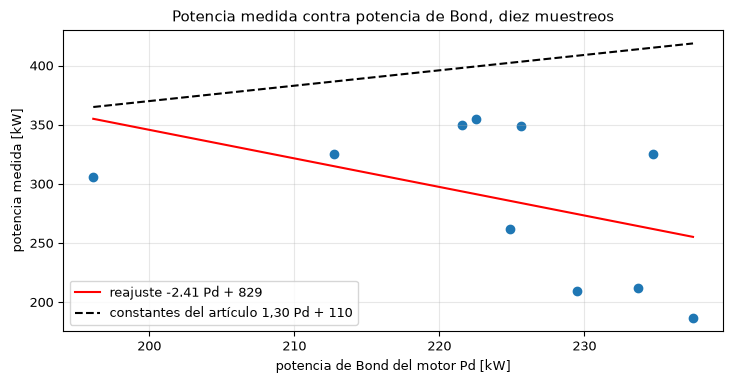

correlación de la potencia medida con la potencia de Bond: -0.453


In [9]:
# Dispersión de la potencia medida contra la potencia de Bond, con la recta reajustada y las constantes del artículo
fig, ax = plt.subplots()
ax.scatter(bond_kw, measured_kw)
line = np.linspace(bond_kw.min(), bond_kw.max(), 20)
ax.plot(line, zeta * line + pn, "r-", label=f"reajuste {zeta:.2f} Pd + {pn:.0f}")
ax.plot(line, 1.30 * line + 110, "k--", label="constantes del artículo 1,30 Pd + 110")
ax.set_xlabel("potencia de Bond del motor Pd [kW]")
ax.set_ylabel("potencia medida [kW]")
ax.set_title("Potencia medida contra potencia de Bond, diez muestreos")
ax.legend()
fig.tight_layout()
plt.show()
corr = np.corrcoef(bond_kw, measured_kw)[0, 1]
print("correlación de la potencia medida con la potencia de Bond:", round(float(corr), 3))

Los diez puntos forman una nube sin relación clara: la recta roja se inclina hacia abajo a través de ellos, la recta negra discontinua de las constantes del artículo queda sobre todos, y la correlación impresa bajo la figura es negativa. La figura muestra por qué no se puede confiar en que un ajuste dentro de la muestra lleve sentido físico con diez puntos y un regresor plano, y por qué el informe del producto mantiene la potencia medida como referencia y no ofrece los kW del modelo como predicción. No muestra qué pasa con un muestreo fuera de los diez; eso es lo que miden las barras con retención de la primera figura, y las barras de potencia dicen que la respuesta no es buena.

## Resultados

**Respuesta:** el protocolo dentro de la muestra es favorable al modelo del HP500 y no puede distinguirlo de un sobreajuste. En tonelaje los errores dentro de la muestra son 11,55 por ciento para el modelo base tal como se entrega, 10,95 para el escalar reajustado, 8,51 para el residuo acotado, 8,24 para la regresión libre y 16,46 para la media constante, y el error baja con el número de parámetros libres entre los modelos ajustados. En potencia el reajuste dentro de la muestra de la forma del artículo da 19,28 por ciento, mejor que las constantes del artículo (47,58 por ciento) y que la potencia de Bond pura (26,88 por ciento), con un coeficiente negativo, zeta = -2,4146, que no tiene sentido físico. Con retención, los mismos modelos puntúan 12,09 (M0), 13,45 (M1), 12,18 (M2) y 18,29 (media) en tonelaje, de modo que M1 pierde 4,94 puntos con la retención y M0 1,14, y 25,94, 25,37, 14,03 y 24,48 en potencia, de modo que la forma reajustada pasa de vencer a la media dentro de la muestra a perder frente a ella.

La primera figura muestra el optimismo como la brecha entre las barras pareadas, la segunda el coeficiente absurdo sobre una nube sin relación. Un validador concluiría que el protocolo del estado del arte es sólido para lo que afirma, una calibración, y mudo sobre lo que el producto quiere afirmar, una predicción; que la regresión sin física ganando la potencia dentro de la muestra y el signo de zeta son la evidencia de que el protocolo no puede discriminar entre modelos; y que retener cada muestreo en turno, con el mismo código, es el paso siguiente, que el notebook 04 mide como la afirmación del producto.

## Resumen

El estado del arte para este chancador ajusta diez muestreos y juzga el ajuste con los mismos diez, un protocolo que favorece al modelo con más libertad: aquí la regresión sin física y un coeficiente de potencia con el signo equivocado. Ejecutados con las funciones públicas de CrusherCal, los mismos modelos con retención dan el optimismo por modelo y objetivo en una sola tabla, y la forma de potencia que superó a la media constante dentro de la muestra pierde frente a ella con retención. La afirmación propia del producto, medida sobre esta base, es el tema del notebook 04.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Koh, E. J. Y., Amini, E., McLachlan, G. J., Beaton, N. (2021), Utilising a deep neural network as a surrogate model to approximate phenomenological models of a comminution circuit for faster simulations, Minerals Engineering 170, 107026. https://doi.org/10.1016/j.mineng.2021.107026